# Enhancing RAG Reasoning with Knowledge Graphs

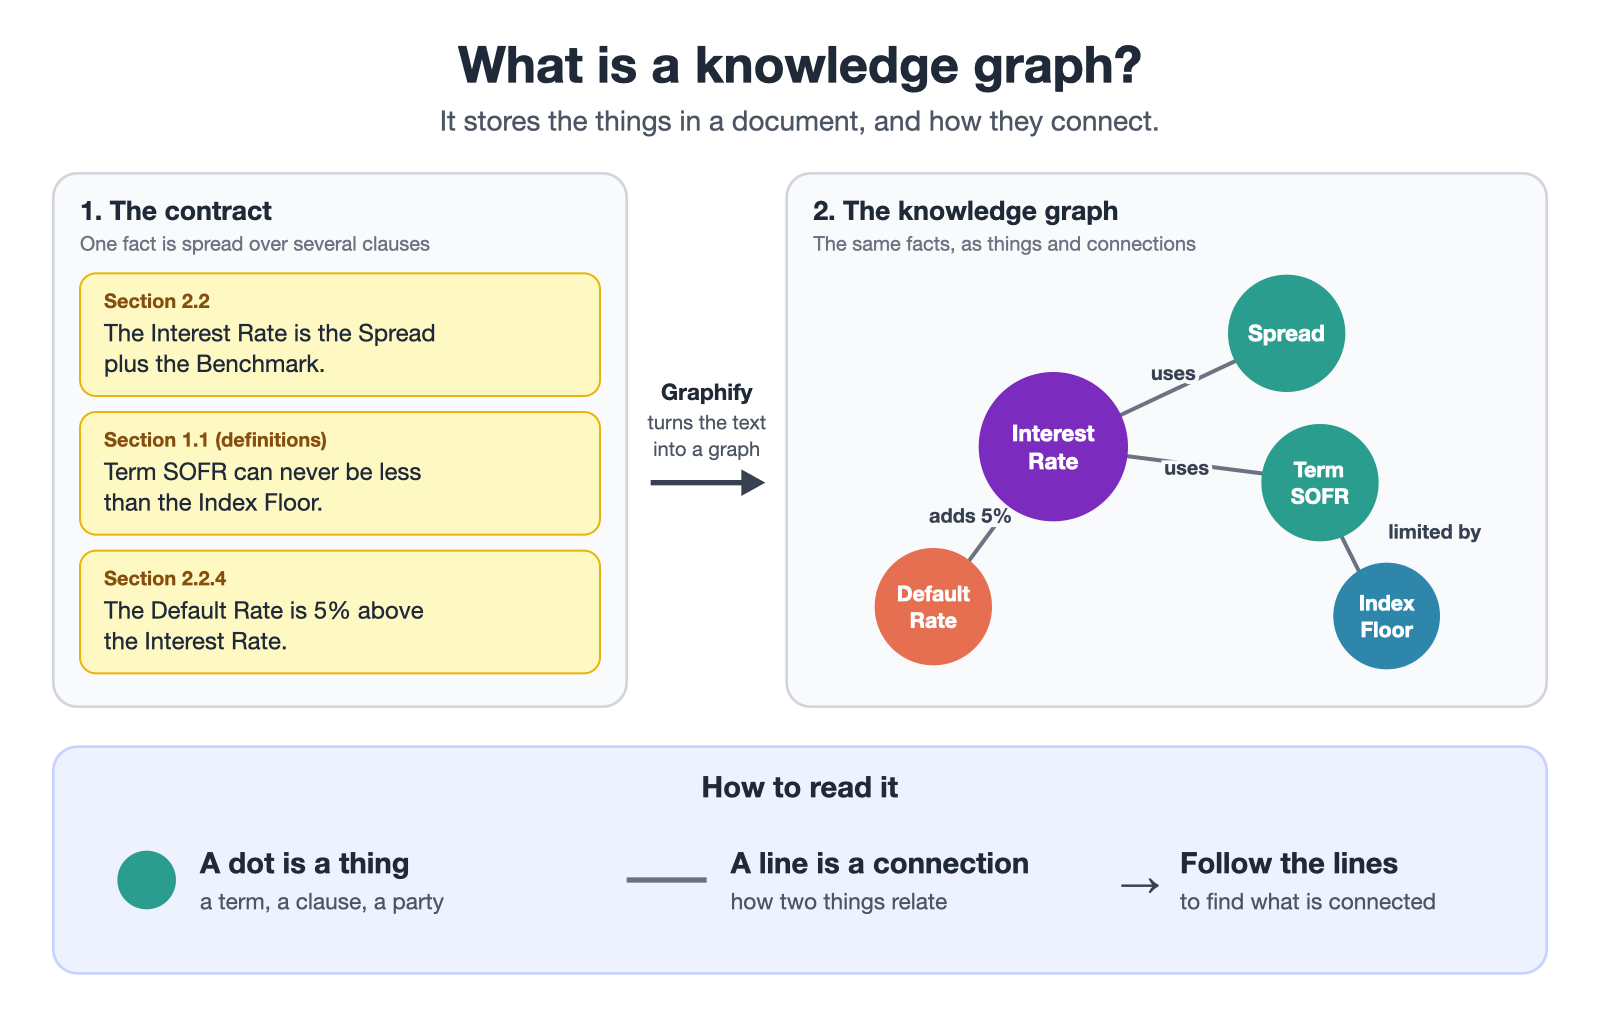

## From Chunks to Connections — Let Your RAG Follow the Links Between Facts

In Lab 2.2, the loan agreement gave vague answers like *"as defined in Section 2.10"*. The answer was spread across several clauses, and the search found only one of them. A search over text chunks finds what *looks similar*. It does not know what is *connected*.

In this lab you fix that. You turn a contract into a **knowledge graph** with **Graphify**, then chat with it and watch which parts of the graph each answer comes from. Everything runs here in Colab. Press **Runtime → Run all**, wait for the last cell to print a link, and click it. The app opens in a new browser tab.

Here's the flow for this lab:

- **Understand the idea.** What a knowledge graph is, and what we build with it (Part 1).
- **Set up Colab.** Install the tools (Part 2).
- **Add the app, piece by piece.** Each piece is explained, so you can see how it works (Parts 3 to 7).
- **Start the app and use it.** Build a graph from a contract and ask it questions (Part 8).

## Prerequisites

✅ **Anthropic API key**: have it ready. You type it into the app, not into this notebook.

✅ **A contract PDF**: for example the Sample Loan Agreement from Lab 2.2.


## Part 1: What Are We Building?

A **knowledge graph** stores a document as **dots** (the things in it) and **lines** (how they connect), like the picture above.

In Lab 2.2, the search found the passage that *looked most similar* to your question, so an answer spread over several clauses was only partly found. In this lab, the **lines** show what else is connected.

Here is what the app does:

1. You upload a contract.
2. **Graphify** turns it into a graph.
3. You ask a question. Claude picks the starting dots, and the app follows their lines (they turn orange).
4. Claude answers from the contract text those dots point to.

**Example:** *"What interest rate applies if Term SOFR is 0.80%?"* The graph connects `Interest Rate` to the `Spread` (4.20%) and to `Term SOFR`, which is limited by the `Index Floor` (1.12606%). So the answer is 4.20% + 1.12606% = **5.32606%**.

## Part 2: Set Up Colab

### Step 1: Install the Tools

**What you're doing**: Installing three tools. A fresh Colab machine knows nothing about graphs, so it does not have them yet:
- **Graphify** reads the contract and builds the graph.
- **Gradio** makes the screen you will use in your browser.
- **Anthropic** is the toolkit that lets the app talk to Claude.

**Why this matters**: Without these, there is nothing to build the graph with and nothing to talk to Claude. The install takes 2 to 4 minutes the first time.

Okay, the tools are installed. But tools alone do nothing. We still need an app that puts them to work. That is what the next parts add.

In [ ]:
!pip install -q "graphifyy[pdf]==0.9.111" gradio anthropic pyboxen

## Part 3: Get the App Ready

Okay, the tools are on the machine. But they are just ingredients. Now we add the app that uses them.

The app is one file, `app.py`. We save it on the Colab machine in 11 pieces (Steps 2 to 12), so you can read what each piece does. Each piece solves one small problem that the piece before it left open:

| Part | Steps | What it does |
|---|---|---|
| **Part 3: Get the App Ready** | 2 to 3 | Load the tools and connect to Claude |
| **Part 4: Turn the Contract into a Graph** | 4 to 5 | Build the graph and keep the contract text |
| **Part 5: Answer Questions from the Graph** | 6 | Use the graph to find and write an answer |
| **Part 6: Draw the Graph** | 7 to 9 | Show the graph as a picture you can move |
| **Part 7: Build the Screen** | 10 to 12 | Add the buttons, the chat and the page around it |

Run the cells **in order, once**. (To run them again, start again from Step 2: it replaces the file.)

### Step 2: Load the Tools and Settings

Let's start with the basics. The app is a Python file, and a Python file has to say which tools it wants to use. So the first thing we do is load them. In code, `import` means "load a ready-made tool". This piece also sets one thing:
- `DEFAULT_MODEL`: the Claude model the app uses unless you change it in the app. 

Okay, the tools are loaded. But the app cannot do anything smart yet, and "smart" here means Claude. So how does the app actually talk to Claude?

In [ ]:
%%writefile app.py
"""
Contract Knowledge Graph: a Gradio app.

1. You paste your Anthropic API key and upload a contract (PDF).
2. Graphify (https://github.com/Graphify-Labs/graphify) turns the contract into a knowledge graph.
3. The graph is drawn on screen. Chat with it on the side.
   For every question, the entities the answer was picked from light up on the graph.

Run it from the Colab notebook (notebook.ipynb), or on your own computer with:
     pip install "graphifyy[pdf]" gradio anthropic pyboxen   then   python app.py
"""
import difflib
import hashlib
import html
import json
import math
import os
import re
import subprocess
import sys
import tempfile
import time
from collections import defaultdict, deque
from pathlib import Path

import anthropic
import gradio as gr
import networkx as nx
from pyboxen import boxen

DEFAULT_MODEL = "claude-haiku-5-5"


def say(text, title, color="white"):
    """Show a message in the notebook output as a box (pyboxen draws it itself, so no print is needed)."""
    boxen(text, title=title, color=color, text_alignment="left", padding=1)



### Step 3: Connect the App to Claude

That is what `ask()` is for. It sends one question to Claude and gives back the reply. It works in two ways:
- **Plain question:** Claude replies with a written answer. This is used for the final answers.
- **With a form:** we also give Claude a form to fill in. A form always has the same shape, so the app can read the reply reliably. This is used to let Claude pick the starting points in the graph.

Your API key is passed in each time it is needed. The app never stores it.

**Result:** the app can now talk to Claude. But there is a problem. Claude has never seen our contract, and a 110-page contract is just a wall of text. How do we turn it into something we can follow by its connections? That is a job for Graphify.

In [ ]:
%%writefile -a app.py
# --------------------------------------------------------------------------------------
# 1. Talk to Claude
# --------------------------------------------------------------------------------------


def ask(key, model, prompt, system=None, form=None, max_tokens=4000):
    """Send one question to Claude. With a `form` (schema), Claude fills it in and we return it."""
    client = anthropic.Anthropic(api_key=key, max_retries=5)
    rules = system or ""
    extra = {}
    if form:
        rules += " Always reply by calling the reply tool."
        extra["tools"] = [{"name": "reply", "description": "Return the result.", "input_schema": form}]
        extra["tool_choice"] = {"type": "tool", "name": "reply"}     # Claude must fill in the form
    if rules:
        extra["system"] = rules.strip()
    r = client.messages.create(model=model, max_tokens=max_tokens,
                               messages=[{"role": "user", "content": prompt}], **extra)
    if form:
        for b in r.content:
            if b.type == "tool_use":
                return b.input
        raise RuntimeError("Claude did not fill in the form. Please try again.")
    return "".join(b.text for b in r.content if b.type == "text").strip()




## Part 4: Turn the Contract into a Graph

### Step 4: Build the Graph with Graphify

What we want is a **map** of the contract: the things in it (a party, a term, a clause) and how they connect. Building that map is exactly what **Graphify** does, using the `ask()` connection to Claude from the last step.
- `run_graphify()` copies the contract PDF to a working folder and starts Graphify as a separate program (`graphify extract`). Graphify reads the contract with Claude and writes the graph. The app shows its progress lines on screen. Your key goes only to that Graphify program and is never written to a file.
- If Graphify says some parts of the contract failed (it keeps going and writes a smaller graph), `run_graphify()` runs it again. Graphify keeps the parts that worked, so only the failed parts are redone.
- `load_graph()` reads the file Graphify produces (`graph.json`) into three lists: the **entities** (dots), the **connections** (lines) and Graphify's **groups** of related entities.

**Result:** we have the map. But look closely and you will find a gap. The map shows *what connects to what*, but not the numbers. Where do the numbers live?

In [ ]:
%%writefile -a app.py
# --------------------------------------------------------------------------------------
# 2. Build the graph with Graphify
# --------------------------------------------------------------------------------------


# Graphify reads the contract in pieces. If one piece fails (a timeout, a rate limit, an answer Claude cut off), Graphify does NOT
# stop: it prints a warning, finishes normally and writes a smaller graph. These are the warnings that mean "some entities are missing".
_INCOMPLETE = re.compile(r"semantic chunk\(s\) failed|semantic extraction is incomplete|invalid JSON, skipping chunk", re.I)
TOKEN_BUDGETS = [None, 30000, 15000]    # one try each. A retry uses smaller pieces, which is Graphify's own advice when parts are skipped


def run_graphify(pdf_path, key, model, out_dir, report=None):
    """Run `graphify extract` on the PDF. Yields the progress lines Graphify prints.
    If Graphify says some parts failed, run it again. Graphify keeps the finished parts, so a retry only redoes the failed ones.
    `report` (a dict) is filled with {"incomplete": True/False, "attempts": n} so the caller can tell the user."""
    report = report if report is not None else {}
    in_dir = Path(out_dir) / "input"
    in_dir.mkdir(parents=True, exist_ok=True)
    target = in_dir / "contract.pdf"
    target.write_bytes(Path(pdf_path).read_bytes())
    # The key is given to the Graphify process only. It is never written to a file.
    env = {**os.environ, "ANTHROPIC_API_KEY": key}
    for attempt, budget in enumerate(TOKEN_BUDGETS, 1):
        cmd = [sys.executable, "-m", "graphify", "extract", str(in_dir), "--backend", "claude",
               "--model", model, "--out", str(Path(out_dir) / "out")]
        if budget:
            cmd += ["--token-budget", str(budget)]
        proc = subprocess.Popen(cmd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        incomplete = False
        for line in proc.stdout:
            incomplete = incomplete or bool(_INCOMPLETE.search(line))
            yield line.rstrip()
        proc.wait()
        if proc.returncode != 0:
            raise RuntimeError("Graphify stopped with an error. See the log above.")
        report.update(incomplete=incomplete, attempts=attempt)
        if not incomplete:
            return
        if attempt < len(TOKEN_BUDGETS):
            yield f"Some parts of the contract were not read. Trying those parts again (attempt {attempt + 1} of {len(TOKEN_BUDGETS)})..."


def load_graph(graph_json):
    """Read Graphify's graph.json into plain dictionaries."""
    data = json.loads(Path(graph_json).read_text())
    nodes = {n["id"]: n for n in data["nodes"]}
    raw = data.get("links") or data.get("edges") or []
    links = [(e["source"], e["target"], e.get("relation", "")) for e in raw if e["source"] in nodes and e["target"] in nodes]
    adj = defaultdict(set)
    for a, b, _ in links:
        if a != b:
            adj[a].add(b)
            adj[b].add(a)
    # Graphify also groups entities that belong together (for example "Interest rate determination").
    groups = (data.get("graph", {}) or {}).get("hyperedges") or data.get("hyperedges") or []
    groups = [g for g in groups if isinstance(g, dict)]
    # A line that points at an entity Graphify never made cannot be drawn. Count those, and the entities left with no line at all.
    stats = {"dropped_edges": len(raw) - len(links), "isolated": sum(1 for n in nodes if n not in adj)}
    return {"nodes": nodes,
            "links": links,
            "adj": {k: sorted(v) for k, v in adj.items()},
            "stats": stats,
            "groups": [{"label": g.get("label", ""), "nodes": [n for n in g.get("nodes", []) if n in nodes]} for g in groups]}




### Step 5: Keep the Contract Text Next to the Graph

They stay in the contract. For example, the `Index Floor` dot does not contain its value (1.12606%). If someone asks "what is the interest rate?", the map alone has no number to give.

So the app also keeps the contract's exact wording. It cuts the PDF into **passages**: one for every defined term and one for every numbered section. `passages_for()` then finds the text a dot points to: the definition of the term, the section it came from, or the places that mention it.

**Result:** the app now has both the map (the graph) and the exact wording (the passages). But having both is not the same as having an answer. What does the app do when someone actually asks a question?

In [ ]:
%%writefile -a app.py
# --------------------------------------------------------------------------------------
# 3. Read the contract text, so answers can use the exact wording
# --------------------------------------------------------------------------------------

_NOISE = re.compile(r"^\s*(KL3 [\d.]+|Sch\. [\d.]+-\d+|[ivxl]+|\d{1,3})\s*$")
_DEF = re.compile(r"^\s*[“\"]?(?P<term>[A-Z][A-Za-z0-9’'\-/&,. ()]{1,70}?)[”\"]?\s*:\s+(?:shall\b|means\b|has\b)")
_SEC = re.compile(r"^\s*(?P<num>\d{1,2}(?:\.\d{1,2}){1,3})\s+(?=[A-Z])")


def contract_passages(pdf_path):
    """Cut the contract into passages: one per defined term, and one per numbered section."""
    from pypdf import PdfReader
    pages = [(p.extract_text() or "") for p in PdfReader(pdf_path).pages]
    lines = [l for l in "\n".join(pages).splitlines() if l.strip() and not _NOISE.match(l)]
    passages, cur = [], None
    for line in lines:
        d, s = _DEF.match(line), _SEC.match(line)
        if d or s:
            cur = {"kind": "def" if d else "section",
                   "key": (d.group("term").strip() if d else s.group("num")), "text": ""}
            passages.append(cur)
        if cur is not None:
            cur["text"] += line.strip() + "\n"
    return passages


def _clean_label(label):
    label = re.sub(r"\s*\(.*?\)", "", label)          # "Spread (4.20%)" -> "Spread"
    return re.sub(r"^\d+(?:\.\d+)*\s+", "", label).strip()   # "5.38 Interest Rate Hedge" -> "Interest Rate Hedge"


def passages_for(node, passages, limit=3):
    """Find the contract text a graph entity points to."""
    found = []
    label = _clean_label(node["label"]).lower()
    for p in passages:                                  # 1) the definition of the term
        if p["kind"] == "def" and p["key"].lower() == label:
            found.append(p)
    for num in re.findall(r"\d+(?:\.\d+)+", node.get("source_location") or ""):   # 2) the section it came from
        found += [p for p in passages if p["kind"] == "section" and (p["key"] == num or p["key"].startswith(num + "."))][:limit]
    if not found and len(label) > 3:                    # 3) otherwise, places that mention it
        found = [p for p in passages if label in p["text"].lower()][:2]
    return found




## Part 5: Answer Questions from the Graph

### Step 6: Answer a Question from the Graph

We could send the whole contract to Claude every time, but that is wasteful. And searching for the one passage that looks most similar misses the connected pieces, which is the problem we saw in Lab 2.2. So instead, the graph decides **where to look**, and the contract text supplies **the exact facts**. A question is answered in three steps:
1. **`pick_start()`:** Claude sees the list of entity names and the question, and picks the 3 to 8 dots to start from. Names are matched forgivingly (capital letters, brackets and small spelling differences do not matter). If no dot matches, the answer is still built from the contract text.
2. **`follow()`:** the app walks along the lines from those dots, up to 2 steps, in both directions and through Graphify's groups. A very busy dot (like `Borrower`, which connects to almost everything) is not walked through, and the walk stops at 30 dots.
3. **`answer()`:** the app collects the contract text those dots point to (definitions first, then sections). It also searches the contract text for key words Claude suggested, finds every passage that literally names what the question is about (so "what depends on the Index Floor?" misses nothing), and pulls in the definitions those passages mention (the `Interest Rate` definition leans on `Spread`), because a graph can miss a clause. Then it asks Claude to answer **using only that text**, with the final answer first. A second pass then checks the draft against the same text, fixes mistakes and adds anything it missed.

**Result:** the app can answer a question, and it knows which dots the answer came from. But the point of this lab is to *see* those dots, not just read the answer. For that we need a picture of the graph.

In [ ]:
%%writefile -a app.py
# --------------------------------------------------------------------------------------
# 4. Ask the graph: pick entities, follow connections, read the passages, answer
# --------------------------------------------------------------------------------------

PICK_FORM = {"type": "object",
             "properties": {"start": {"type": "array", "items": {"type": "string"}},
                            "search_terms": {"type": "array", "items": {"type": "string"}},
                            "subjects": {"type": "array", "items": {"type": "string"}}},
             "required": ["start", "search_terms", "subjects"]}
STEPS, MAX_NODES, BUSY, MAX_PASSAGES, MAX_SEARCH = 2, 30, 25, 26, 8   # how far to walk, and how much to collect


def _norm(label):
    """A name in its plainest form, so 'Interest Rate (4.20%)', 'interest  rate' and 'Interest Rate' all match."""
    return re.sub(r"[^a-z0-9]+", " ", _clean_label(label).lower()).strip()


def pick_start(key, model, graph, question):
    names = "\n".join(f"{n['label']}" for n in graph["nodes"].values())
    out = ask(key, model, f"Entities:\n{names}\n\nQuestion: {question}",
              system="You search a knowledge graph of a loan agreement. Pick 3 to 8 entity names, copied EXACTLY from the list, "
                     "that the question is about or that are the best entry points to the facts it needs. Also give 6 to 10 search_terms: words or short "
                     "phrases likely to appear in the contract wording that holds the answer, including the clause names a lawyer would use "
                     "(for an interest question: the rate, the spread or margin, the floor, how interest is calculated). "
                     "Also give subjects: the exact defined terms or clause names the question is about (for example the term whose "
                     "change or effect is asked about). Copy them the way the contract writes them.",
              form=PICK_FORM, max_tokens=600)
    by_name = defaultdict(list)                      # several entities can share one name: keep them all
    for nid, n in graph["nodes"].items():
        by_name[_norm(n["label"])].append(nid)
    ids = []
    for s in out.get("start", []):
        name = _norm(s) if isinstance(s, str) else ""
        if name and name not in by_name:             # Claude changed a word or two: take the closest name, if it is very close
            close = difflib.get_close_matches(name, list(by_name), n=1, cutoff=0.88)
            name = close[0] if close else ""
        ids += by_name.get(name, [])
    clean = lambda key: [t.strip() for t in out.get(key, []) if isinstance(t, str) and len(t.strip()) > 2]
    return list(dict.fromkeys(ids)), clean("search_terms")[:10], clean("subjects")[:5]


def mentioning(passages, subjects, skip, limit=24):
    """Every place in the contract that literally names the subject. This is what answers 'what depends on X?': nothing is skipped
    just because the graph has no line for it."""
    scored = []
    for p in passages:
        if (p["kind"], p["key"]) in skip:
            continue
        score = 0
        for s in subjects:
            n = len(re.findall(r"(?<![A-Za-z])" + re.escape(s) + r"(?![A-Za-z])", p["text"], flags=re.I))
            score += n + (20 if p["key"].lower() == s.lower() else 0)
        if score:
            scored.append((score, p))
    return [p for _, p in sorted(scored, key=lambda x: -x[0])[:limit]]


def search_passages(passages, terms, skip, limit=MAX_SEARCH):
    """The graph can miss a clause (for example, if no dot was made for it). So also search the contract text for the key words."""
    scored = []
    for p in passages:
        if (p["kind"], p["key"]) in skip:
            continue
        text, key = p["text"].lower(), p["key"].lower()
        score = sum(min(text.count(t.lower()), 5) + (30 if t.lower() == key else 8 if t.lower() in key else 0) for t in terms)
        if score:
            scored.append((score, p))
    return [p for _, p in sorted(scored, key=lambda x: -x[0])[:limit]]


def referenced_defs(passages, chosen, seen, limit=12):
    """A definition often leans on other defined terms (the Interest Rate is 'the Spread plus the Benchmark'). Add those definitions too."""
    defs = {p["key"]: p for p in passages if p["kind"] == "def" and len(p["key"]) >= 4 and ("def", p["key"]) not in seen}
    spread = {k: sum(k in p["text"] for p in passages) for k in defs}     # in how many passages each term appears
    common = {k for k, n in spread.items() if n > len(passages) * 0.1}      # Lender, Borrower, Loan... are everywhere: skip
    hits = defaultdict(int)
    for c in chosen:
        for key in defs:
            if key not in common and re.search(r"(?<![A-Za-z])" + re.escape(key) + r"(?![A-Za-z])", c["text"]):
                hits[key] += 1
    ranked = sorted(hits, key=lambda k: (-hits[k], spread[k]))[:limit]   # rarer terms first: they are the specific ones
    return [defs[k] for k in ranked]


def follow(graph, start):
    """Walk the connections (both directions, and through Graphify's groups) and collect the entities we meet."""
    adj = defaultdict(set, {k: set(v) for k, v in graph["adj"].items()})
    for g in graph["groups"]:
        for a in g["nodes"]:
            adj[a].update(n for n in g["nodes"] if n != a)
    found, queue = list(start), deque((s, 0) for s in start)
    while queue and len(found) < MAX_NODES:
        k, d = queue.popleft()
        if d >= STEPS or (len(adj[k]) > BUSY and k not in start):
            continue
        for nb in sorted(adj[k], key=lambda x: len(adj[x])):
            if nb not in found and len(found) < MAX_NODES:
                found.append(nb)
                queue.append((nb, d + 1))
    return found


MAX_CONTEXT = 90000     # characters of contract text sent to Claude (about 22,000 tokens)


def answer(key, model, graph, passages, question):
    start, terms, subjects = pick_start(key, model, graph, question)
    picked = follow(graph, start)       # with no start entity this is empty: the contract text search below still finds the answer
    nodes = graph["nodes"]
    # 1) the contract text the picked entities point to (definitions first, then sections)
    graph_chosen, seen = [], set()
    for kind in ("def", "section"):
        for nid in picked:
            for p in passages_for(nodes[nid], passages):
                sig = (p["kind"], p["key"])
                if p["kind"] == kind and sig not in seen and len(graph_chosen) < MAX_PASSAGES:
                    seen.add(sig)
                    graph_chosen.append(p)
    # 2) everything that literally names the subject of the question, and clauses found by the key words
    named = mentioning(passages, subjects, set())
    sigs = lambda ps: {(p["kind"], p["key"]) for p in ps}
    found = search_passages(passages, terms, sigs(named))
    # 3) definitions that those passages lean on (the Interest Rate leans on the Spread)
    lead = named + found
    pulled = referenced_defs(passages, lead + [p for p in graph_chosen if p["kind"] == "def"][:12], sigs(lead))
    chosen, used, size = [], set(), 0
    for p in lead + pulled + graph_chosen:
        sig = (p["kind"], p["key"])
        if sig in used or size > MAX_CONTEXT:
            continue
        used.add(sig)
        chosen.append(p)
        size += min(len(p["text"]), 2500)
    if not chosen:
        return None
    context = "\n\n".join(f"[{('Definition' if p['kind'] == 'def' else 'Section')}: {p['key']}]\n{p['text'][:2500]}" for p in chosen)
    inside = set(picked)
    links = "\n".join(f"{nodes[a]['label']} -> {nodes[b]['label']}" for a, b, _ in graph["links"] if a in inside and b in inside)
    material = (f"Entities picked from the knowledge graph, and how they connect:\n{links}\n\n"
                f"Contract passages:\n{context}\n\nQuestion: {question}")
    rules = ("Answer using ONLY the contract passages. Name the sections or defined terms you use, quote the key words, and show any "
             "calculation step by step. If a definition names another defined term, use that term's own definition from the passages. "
             "For a question about what would be affected, list EVERY passage that names the subject, directly or through another term, "
             "and say why. Say something is missing only if it truly is not in any passage. Put the final answer first, then a short bullet list.")
    draft = ask(key, model, material, system=rules, max_tokens=3000)
    # 4) a second look: check the draft against the passages, fix mistakes, add what it missed
    text = ask(key, model,
               f"{material}\n\nDraft answer:\n{draft}",
               system="You are a careful reviewer. Check every statement and number in the draft against the contract passages. Fix anything "
                      "wrong, remove anything the passages do not support, and add any provision or value the passages show that the draft "
                      "missed or wrongly called missing. Redo any arithmetic. Reply with the corrected final answer only, in the same format "
                      "(final answer first, then a short bullet list). Do not mention the draft or the review.",
               max_tokens=3000)
    return {"text": text, "start": start, "picked": picked, "passages": [(p["kind"], p["key"]) for p in chosen]}


## Part 6: Draw the Graph

### Step 7: Decide Where Each Dot Goes

Drawing a graph sounds simple, but there is a catch. A graph with around 200 dots looks like a mess if the dots are placed at random. Connected dots should sit close together, so the picture shows how the contract is organized.

That is what `make_layout()` does. The main cluster gets most of the picture, and the small groups that are not connected to anything go in a strip at the bottom. This piece also holds the colors and two tiny helpers.

Okay, every dot now has a place. But a place is just a pair of numbers. Who turns those into a picture you can actually move around?

In [ ]:
%%writefile -a app.py
# --------------------------------------------------------------------------------------
# 5. Draw the graph
# --------------------------------------------------------------------------------------

PALETTE = ["#2a9d8f", "#2e86ab", "#7b2cbf", "#e76f51", "#6a994e", "#c9184a", "#e9c46a", "#3a86ff"]
W, H = 1000, 680


def _fit(raw, pos, x0, x1, y0, y1):
    """Place a small layout inside a box of the canvas (all numbers are between 0 and 1)."""
    xs, ys = [p[0] for p in raw.values()], [p[1] for p in raw.values()]
    lo_x, hi_x, lo_y, hi_y = min(xs), max(xs), min(ys), max(ys)
    for n, (x, y) in raw.items():
        fx = 0.5 if hi_x == lo_x else (x - lo_x) / (hi_x - lo_x)
        fy = 0.5 if hi_y == lo_y else (y - lo_y) / (hi_y - lo_y)
        pos[n] = (x0 + fx * (x1 - x0), y0 + fy * (y1 - y0))


def make_layout(graph):
    """Connected dots sit close together. The main group gets the canvas; tiny loose groups go in a strip at the bottom."""
    G = nx.Graph()
    G.add_nodes_from(graph["nodes"])
    G.add_edges_from((a, b) for a, b, _ in graph["links"])
    comps = sorted(nx.connected_components(G), key=len, reverse=True)
    pos = {}
    main = G.subgraph(comps[0])
    raw = nx.spring_layout(main, seed=7, k=2.5 / math.sqrt(max(len(main), 1)), iterations=400)
    _fit({n: (float(x), float(y)) for n, (x, y) in raw.items()}, pos, 0.04, 0.96, 0.04, 0.80)
    small = comps[1:]
    for i, c in enumerate(small):
        cell = 0.92 / len(small)
        sub = G.subgraph(c)
        raw = nx.spring_layout(sub, seed=7) if len(sub) > 1 else {n: (0.0, 0.0) for n in sub}
        _fit({n: (float(x), float(y)) for n, (x, y) in raw.items()}, pos,
             0.04 + i * cell + cell * 0.2, 0.04 + (i + 1) * cell - cell * 0.2, 0.89, 0.96)
    return pos


def esc(s):
    return str(s).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;").replace('"', "&quot;")


def short(label, n=26):
    s = re.sub(r"\s*\(.*?\)", "", label).strip()
    return s if len(s) <= n else s[: n - 1] + "…"




### Step 8: Build the Picture That Moves

A normal chart would be flat and fixed. We want one you can play with. So the app uses a small web page that draws the graph **in your browser**. It is written in HTML and JavaScript (the language of web pages), and it makes the graph feel alive:
- Every dot pushes the other dots away, and every line pulls its two dots together, like a spring.
- You can **drag** a dot, **zoom** with the mouse wheel, and **drag the background** to move around.
- **Hover** over a dot to read it. **Click** a dot to see all its connections.

But this page is only a blank template. It does not know our graph yet. How do we give it the graph?

In [ ]:
%%writefile -a app.py
GRAPH_PAGE = r"""<!doctype html><html><head><meta charset="utf-8"><style>
html,body{margin:0;height:100%;background:#fff;font:12px/1.45 sans-serif;color:#111;overflow:hidden}
#wrap{position:relative;width:100%;height:100%}
canvas{width:100%;height:100%;display:block;cursor:grab;touch-action:none}
#tools{position:absolute;top:8px;left:8px;display:flex;gap:4px}
#tools button{width:30px;height:30px;border:1px solid #ccc;background:#fff;border-radius:6px;font-size:16px;cursor:pointer;color:#333}
#tools button:hover{background:#f2f2f2}
#hint{position:absolute;top:12px;left:112px;color:#888;font-size:11px}
#tip{position:absolute;pointer-events:none;background:rgba(255,255,255,.97);border:1px solid #ccc;border-radius:6px;padding:6px 8px;max-width:270px;display:none;box-shadow:0 2px 8px rgba(0,0,0,.15)}
</style></head><body><div id="wrap"><canvas id="c"></canvas>
<div id="tools"><button id="zi" title="Zoom in">+</button><button id="zo" title="Zoom out">&minus;</button><button id="fit" title="Fit everything on screen">&#9635;</button></div>
<div id="hint">Drag a dot &middot; scroll to zoom &middot; drag the background to move &middot; click a dot to see its details</div>
<div id="tip"></div></div>
<script>
const D = __DATA__;
const cv = document.getElementById('c'), ctx = cv.getContext('2d'), tip = document.getElementById('tip');
let touched = false, cw = 0, ch = 0, dpr = 1, k = 1, tx = 0, ty = 0, alpha = 0, dirty = true, hover = -1, sel = -1, drag = null, pan = null, down = null;
const N = D.nodes.map((n, i) => Object.assign({}, n, {i: i, x: n.ux * D.w, y: n.uy * D.h, vx: 0, vy: 0, pinned: false}));
const L = D.links.map(l => ({s: N[l[0]], t: N[l[1]], rel: l[2], len: Math.max(20, Math.hypot(N[l[0]].x - N[l[1]].x, N[l[0]].y - N[l[1]].y))}));
const nb = N.map(() => []);
L.forEach(l => { nb[l.s.i].push([l.t.i, l.rel, '->']); nb[l.t.i].push([l.s.i, l.rel, '<-']); });
const anyHot = N.some(n => n.hot);
const byDeg = N.slice().sort((a, b) => b.deg - a.deg);

function resize() {
  dpr = window.devicePixelRatio || 1; cw = cv.clientWidth; ch = cv.clientHeight;
  cv.width = cw * dpr; cv.height = ch * dpr; dirty = true;
}
function fit() {
  if (cw < 50 || ch < 50) return;     // the frame is not laid out yet; the resize handler fits again once it is
  let x0 = 1e9, x1 = -1e9, y0 = 1e9, y1 = -1e9;
  N.forEach(n => { x0 = Math.min(x0, n.x); x1 = Math.max(x1, n.x); y0 = Math.min(y0, n.y); y1 = Math.max(y1, n.y); });
  const w = Math.max(x1 - x0, 1), h = Math.max(y1 - y0, 1);
  k = Math.min((cw - 60) / w, (ch - 60) / h); tx = (cw - w * k) / 2 - x0 * k; ty = (ch - h * k) / 2 - y0 * k; dirty = true;
}
function zoomAt(sx, sy, f) {
  touched = true; const nk = Math.min(8, Math.max(0.25, k * f));
  tx = sx - (sx - tx) * nk / k; ty = sy - (sy - ty) * nk / k; k = nk; dirty = true;
}
function focus() { return sel >= 0 ? sel : hover; }

function tick() {            // the dots push each other away; lines pull connected dots back to their resting length
  if (alpha < 0.003) return;
  for (let i = 0; i < N.length; i++) for (let j = i + 1; j < N.length; j++) {
    const a = N[i], b = N[j]; let dx = a.x - b.x, dy = a.y - b.y, d = Math.hypot(dx, dy) || 0.1;
    if (d > 140) continue;
    const f = 110 * alpha / d / d; dx *= f; dy *= f;
    if (!a.pinned) { a.vx += dx; a.vy += dy; } if (!b.pinned) { b.vx -= dx; b.vy -= dy; }
  }
  L.forEach(l => {
    const dx = l.t.x - l.s.x, dy = l.t.y - l.s.y, d = Math.hypot(dx, dy) || 0.1, f = (d - l.len) / d * 0.12 * Math.min(1, alpha * 3);
    if (!l.s.pinned) { l.s.vx += dx * f; l.s.vy += dy * f; } if (!l.t.pinned) { l.t.vx -= dx * f; l.t.vy -= dy * f; }
  });
  N.forEach(n => { if (n.pinned) return; n.vx *= 0.7; n.vy *= 0.7; n.x += n.vx; n.y += n.vy; });
  alpha *= 0.975; dirty = true;
}

function draw() {
  ctx.setTransform(dpr, 0, 0, dpr, 0, 0); ctx.clearRect(0, 0, cw, ch);
  const f = focus(), fs = f >= 0 ? new Set([f].concat(nb[f].map(a => a[0]))) : null;
  ctx.save(); ctx.translate(tx, ty); ctx.scale(k, k);
  L.forEach(l => {
    let col = '#bbb', lw = 0.9, al = 0.8;
    if (fs) { const on = l.s.i === f || l.t.i === f; col = on ? '#1d4ed8' : '#ccc'; lw = on ? 2.4 : 0.6; al = on ? 1 : 0.12; }
    else if (anyHot) { const on = l.s.hot && l.t.hot; col = on ? '#f77f00' : '#ccc'; lw = on ? 2.4 : 0.6; al = on ? 1 : 0.28; }
    ctx.globalAlpha = al; ctx.strokeStyle = col; ctx.lineWidth = lw / Math.sqrt(k);
    ctx.beginPath(); ctx.moveTo(l.s.x, l.s.y); ctx.lineTo(l.t.x, l.t.y); ctx.stroke();
  });
  N.forEach(n => {
    const al = fs ? (fs.has(n.i) ? 1 : 0.15) : (anyHot ? (n.hot ? 1 : 0.18) : 1);
    ctx.globalAlpha = al; ctx.fillStyle = n.hot ? '#f77f00' : n.color;
    ctx.beginPath(); ctx.arc(n.x, n.y, n.r, 0, 6.2832); ctx.fill();
    if (n.start || n.i === f || n.pinned || (n.hot && !fs)) { ctx.lineWidth = (n.start || n.i === f ? 2.5 : 1.2) / Math.sqrt(k); ctx.strokeStyle = '#111'; ctx.stroke(); }
  });
  ctx.restore(); ctx.globalAlpha = 1;
  // names (drawn in screen space so they stay the same size; skipped when they would overlap)
  let order;
  if (fs) order = [f].concat(nb[f].map(a => a[0]).sort((a, b) => N[b].deg - N[a].deg));
  else if (anyHot) order = N.filter(n => n.hot).sort((a, b) => (b.start - a.start) || (b.deg - a.deg)).map(n => n.i);
  else order = byDeg.slice(0, k < 0.8 ? 22 : k < 1.4 ? 38 : k < 2.2 ? 90 : 999).map(n => n.i);
  const placed = []; ctx.font = '600 11px sans-serif'; ctx.textBaseline = 'middle';
  order.forEach(i => {
    const n = N[i], text = n.short, w = ctx.measureText(text).width, r = n.r * k;
    let x = n.x * k + tx + r + 3; const y = n.y * k + ty;
    if (x + w > cw - 4) x = n.x * k + tx - r - 3 - w;
    if (x < 2 || y < 6 || y > ch - 6) return;
    const box = [x - 2, y - 7, x + w + 2, y + 7];
    if (placed.some(p => !(box[2] < p[0] || box[0] > p[2] || box[3] < p[1] || box[1] > p[3]))) return;
    placed.push(box); ctx.lineWidth = 3; ctx.strokeStyle = '#fff'; ctx.strokeText(text, x, y); ctx.fillStyle = '#111'; ctx.fillText(text, x, y);
  });
}

function hit(sx, sy) {
  const wx = (sx - tx) / k, wy = (sy - ty) / k;
  for (let i = N.length - 1; i >= 0; i--) { const n = N[i], r = n.r + 3 / k; if ((n.x - wx) * (n.x - wx) + (n.y - wy) * (n.y - wy) <= r * r) return i; }
  return -1;
}
function esc(s) { return String(s).replace(/[&<>"]/g, c => ({'&': '&amp;', '<': '&lt;', '>': '&gt;', '"': '&quot;'}[c])); }
function showTip(h, sx, sy) {
  if (h < 0) { tip.style.display = 'none'; return; }
  const n = N[h];
  tip.innerHTML = '<b>' + esc(n.label) + '</b>' + (n.loc ? '<div class="r">' + esc(n.loc) + '</div>' : '') +
    (n.why ? '<div>' + esc(n.why.slice(0, 220)) + '</div>' : '') + '<div class="r">' + nb[h].length + ' connections. Click to list them.</div>';
  tip.style.display = 'block';
  tip.style.left = Math.min(sx + 14, cw - 280) + 'px'; tip.style.top = Math.min(sy + 14, ch - 90) + 'px';
}
function send(node) { try { window.parent.postMessage({kgInfo: true, node: node}, '*'); } catch (err) {} }
function renderInfo() {      // the details of the clicked dot are shown in the "Node details" card next to the graph
  if (sel < 0) { send(null); return; }
  const n = N[sel];
  send({label: n.label, loc: n.loc, why: n.why, total: nb[sel].length,
        conns: nb[sel].slice(0, 40).map(a => ({dir: a[2], label: N[a[0]].label, rel: a[1].replace(/_/g, ' ')}))});
}
function pt(e) { const r = cv.getBoundingClientRect(); return [e.clientX - r.left, e.clientY - r.top]; }

cv.addEventListener('pointerdown', e => {
  touched = true;
  cv.setPointerCapture(e.pointerId); const p = pt(e), h = hit(p[0], p[1]); down = {sx: p[0], sy: p[1], moved: false, h: h};
  if (h >= 0) { drag = N[h]; drag.pinned = true; alpha = 0.4; } else { pan = {tx: tx, ty: ty, sx: p[0], sy: p[1]}; cv.style.cursor = 'grabbing'; }
});
cv.addEventListener('pointermove', e => {
  const p = pt(e);
  if (down) {
    if (Math.hypot(p[0] - down.sx, p[1] - down.sy) > 3) down.moved = true;
    if (drag && down.moved) { drag.x = (p[0] - tx) / k; drag.y = (p[1] - ty) / k; alpha = Math.max(alpha, 0.3); tip.style.display = 'none'; }
    else if (pan) { tx = pan.tx + (p[0] - pan.sx); ty = pan.ty + (p[1] - pan.sy); }
  } else { const h = hit(p[0], p[1]); if (h !== hover) hover = h; showTip(h, p[0], p[1]); cv.style.cursor = h >= 0 ? 'pointer' : 'grab'; }
  dirty = true;
});
cv.addEventListener('pointerup', e => {
  if (down && !down.moved) { sel = down.h >= 0 && sel !== down.h ? down.h : -1; renderInfo(); if (drag) drag.pinned = false; }
  drag = null; pan = null; down = null; cv.style.cursor = 'grab'; dirty = true;
});
cv.addEventListener('pointerleave', () => { if (!down) { hover = -1; tip.style.display = 'none'; dirty = true; } });
cv.addEventListener('wheel', e => { e.preventDefault(); touched = true; const p = pt(e); zoomAt(p[0], p[1], Math.exp(-e.deltaY * 0.0016)); }, {passive: false});
document.getElementById('zi').onclick = () => zoomAt(cw / 2, ch / 2, 1.35);
document.getElementById('zo').onclick = () => zoomAt(cw / 2, ch / 2, 1 / 1.35);
document.getElementById('fit').onclick = fit;
// the page may be laid out after it loads (the frame grows to its final size): keep the whole graph in view until the user moves it
new ResizeObserver(() => { resize(); if (!touched) fit(); }).observe(cv);
window.addEventListener('resize', () => { resize(); if (!touched) fit(); });
resize(); fit(); send(null);
(function loop() { tick(); if (dirty) { draw(); dirty = false; } requestAnimationFrame(loop); })();
</script></body></html>"""




### Step 9: Draw the Graph and Highlight the Answer

That is the job of `draw()`. It takes the template from the last step and fills it. It sends the dots, the lines and the positions from Step 7. It also marks the dots the last answer used, which turn **orange**, and adds the color key and the "How to read this" text under the picture.

**Result:** the app can now draw the graph and show exactly where an answer came from. We have all the abilities. But a person cannot use abilities directly. They need a screen with somewhere to type and something to click. That is the last job.

In [ ]:
%%writefile -a app.py
def draw(graph, pos, picked=(), start=()):
    """The graph as an interactive picture: drag dots, scroll to zoom, drag the background to move, click a dot for its connections.
    Picked entities are orange; everything else is faded."""
    on, starts = set(picked), set(start)
    nodes = graph["nodes"]
    index = {nid: i for i, nid in enumerate(nodes)}
    deg = {k: len(v) for k, v in graph["adj"].items()}
    # one color per big topic group (Graphify's "community"); the rest are grey
    sizes = {}
    for n in nodes.values():
        sizes[n.get("community")] = sizes.get(n.get("community"), 0) + 1
    ranked = [c for c, _ in sorted(sizes.items(), key=lambda kv: -kv[1])][: len(PALETTE)]
    color = {c: PALETTE[i] for i, c in enumerate(ranked)}
    data = {
        "w": W, "h": H,
        "nodes": [{"label": n["label"], "short": short(n["label"]), "loc": n.get("source_location") or "",
                   "why": n.get("rationale") or "", "color": color.get(n.get("community"), "#9aa5b1"),
                   "ux": pos[nid][0], "uy": pos[nid][1], "deg": deg.get(nid, 0),
                   "r": round(4 + min(deg.get(nid, 0), 14) * 0.8 + (3 if nid in on else 0), 1),
                   "hot": nid in on, "start": nid in starts} for nid, n in nodes.items()],
        "links": [[index[a], index[b], rel] for a, b, rel in graph["links"]],
    }
    page = GRAPH_PAGE.replace("__DATA__", json.dumps(data).replace("</", "<\\/"))
    frame = (f'<iframe srcdoc="{html.escape(page, quote=True)}" sandbox="allow-scripts" '
             f'style="width:100%;height:{H}px;border:1px solid #ddd;border-radius:8px;background:#fff"></iframe>')
    # color key: each color is a group of related topics, named after its most connected entity
    key = []
    for c in ranked:
        top = max((k for k, n in nodes.items() if n.get("community") == c), key=lambda k: deg.get(k, 0))
        key.append(f'<span style="margin-right:14px;white-space:nowrap"><span style="display:inline-block;width:11px;height:11px;border-radius:50%;'
                   f'background:{color[c]};vertical-align:-1px"></span> {esc(short(nodes[top]["label"], 22))}</span>')
    guide = ('<div style="font:13px/1.5 sans-serif;color:var(--body-text-color, #555);margin-top:8px">'
             '<b>How to read this.</b> Each dot is something in the contract (a term, a clause, a party). A line means the two are connected. '
             'Bigger dots are connected to more things. Colors group related topics, named after the biggest dot in each group: '
             + "".join(key) + '.<br>'
             '<b>Move around.</b> Drag a dot to move it (it stays where you put it). Scroll to zoom in and out. Drag the empty background to move the whole graph. '
             'Hover over a dot to read it. Click a dot to see its details and everything it is connected to in the <b>Node details</b> box on the right.<br>'
             '<b>What to do next.</b> Ask a question on the right. The dots the answer was picked from turn '
             '<b style="color:#f77f00">orange</b> (thick outline = where the search started), and everything else fades.</div>')
    return frame + guide


def building_html(stage, log, started):
    """Shown where the graph will appear while it is being built: a moving bar, the time so far, and Graphify's latest lines."""
    secs = int(time.time() - started)
    lines = "".join(f"<div>{html.escape(l[:260])}</div>" for l in log[-10:]) or "<div>Waiting for Graphify to start…</div>"
    return ('<style>@keyframes kgslide{0%{margin-left:-35%}100%{margin-left:100%}}</style>'
            '<div style="border:1px dashed #bbb;border-radius:8px;padding:70px 28px;text-align:center;font:15px sans-serif;color:var(--body-text-color, #555)">'
            f'<div style="font-weight:600;font-size:18px">{html.escape(stage)}</div>'
            f'<div style="margin-top:4px;color:#888">{secs // 60}:{secs % 60:02d} so far. A long contract takes a few minutes. Keep this tab open.</div>'
            '<div style="margin:18px auto;max-width:420px;height:6px;border-radius:3px;background:#eee;overflow:hidden">'
            '<div style="width:35%;height:100%;background:#f77f00;animation:kgslide 1.4s linear infinite"></div></div>'
            f'<div style="font:12px/1.5 monospace;color:#777;text-align:left;max-width:560px;margin:0 auto;overflow:hidden">{lines}</div></div>')


def empty_graph_html():
    return ('<div style="border:1px dashed #bbb;border-radius:8px;padding:120px 20px;text-align:center;font:15px sans-serif;color:#777">'
            'Your graph will appear here.<br>Add your key, then upload the contract and build the graph.</div>')




## Part 7: Build the Screen

### Step 10: Prepare the Chat

Let's start with the words on that screen. A chat needs a welcome message, a few example questions to get people started, and a place that explains each answer. So this piece holds the two example questions, the welcome messages, and `picked_panel()`, which builds the "Where this answer came from" box that is added to the end of each answer in the chat. That box lists the entities an answer came from and the contract sections it read.

Okay, we have the words. But words do nothing until a button triggers some work. So what happens when someone presses a button?

In [ ]:
%%writefile -a app.py
# --------------------------------------------------------------------------------------
# 6. The screen
# --------------------------------------------------------------------------------------

EXAMPLES = ["One-month Term SOFR is currently 0.80%. What interest rate does the Borrower pay on the Loan? Show your work.",
            "If the Index Floor were renegotiated, which provisions of the agreement would be affected? List each one and say why."]


START_MESSAGE = "Hi! First add your key, then upload the contract and build the graph. After that, ask me anything about the contract here."
READY_MESSAGE = ("The graph is ready. Ask me anything about the contract, or try one of the example questions. "
                 "The dots I use for each answer light up in orange on the graph.")


def start_chat():
    return [{"role": "assistant", "content": START_MESSAGE}]


def ready_chat():
    return [{"role": "assistant", "content": READY_MESSAGE}]


def picked_panel(nodes, res):
    """A small box added to the end of each answer in the chat: which entities the answer came from, and which contract text was read."""
    chips = "".join(f'<span class="chip{" start" if n in res["start"] else ""}">{html.escape(nodes[n]["label"])}</span>' for n in res["picked"])
    read = ", ".join(f"{'definition of ' if k == 'def' else 'Section '}{v}" for k, v in res["passages"]) or "none"
    return ('\n\n<div class="picked"><div class="picked-title">Where this answer came from</div>'
            '<div class="picked-sub">The graph picked these entities. The outlined ones are where the search started.</div>'
            f'<div class="chips">{chips}</div>'
            f'<div class="picked-sub" style="margin-top:8px"><b>Contract text it read:</b> {html.escape(read)}</div></div>')


### Step 11: Wire Up the Buttons

Each button runs one function, and each function uses the steps we built before:
- **`build()`** (Build graph): checks that you gave a key and a contract, runs Graphify (Step 4) while showing a live progress panel where the graph will appear, reads the contract text (Step 5), and draws the graph (Step 9). When it finishes, it tells you how many entities have no connection and warns you if Graphify could not read the whole contract. Press **Build graph** again to retry only the missing parts.
- **`chat()`** (Ask): runs "Answer a question from the graph" (Step 6), shows the answer with its "Where this answer came from" box, and lights up the dots it came from.

Okay, the buttons now know what to do. But they are still loose parts lying around. Something has to put them on one screen.

In [ ]:
%%writefile -a app.py
def build(pdf, key, model, state):
    if not key or not key.strip():
        raise gr.Error("Please enter your Anthropic API key.")
    if pdf is None:
        raise gr.Error("Please upload the contract (PDF).")
    key, model = key.strip(), (model or DEFAULT_MODEL).strip()
    try:        # a 2-second test, so a wrong key, model name or empty credit is reported clearly instead of failing inside Graphify
        ask(key, model, "Reply with the word OK.", max_tokens=10)
    except Exception as e:
        say(str(e)[:400], "Claude did not accept the key or model", "red")
        raise gr.Error(f"Claude did not accept the key or the model '{model}': {str(e)[:250]}")
    # Same contract and model = same folder, so pressing "Build graph" again reuses what Graphify already finished and only redoes the rest.
    digest = hashlib.sha1(Path(pdf).read_bytes() + model.encode()).hexdigest()[:12]
    work = str(Path(tempfile.gettempdir()) / f"graphify_app_{digest}")
    report, log, started = {}, [], time.time()
    say("Starting Graphify. This takes a few minutes for a long contract.", "Build", "cyan")
    yield "Starting Graphify. This takes a few minutes for a long contract.", building_html("Building your graph…", log, started), state, gr.update()
    try:
        for line in run_graphify(pdf, key, model, work, report):
            if line.strip():
                log.append(line.replace(key, "***"))
                yield "**Building the graph…**", building_html("Building your graph…", log, started), state, gr.update()
    except Exception as e:
        say("\n".join(log[-25:] + [str(e)[:300]]), "Build failed", "red")
        raise gr.Error("Could not build the graph. The last Graphify lines were: " + " | ".join(l[:160] for l in log[-4:]))
    say("\n".join(log[-6:]) or "Graphify finished.", "Graphify log", "blue")
    built = Path(work) / "out" / "graphify-out" / "graph.json"
    graph = load_graph(built)
    yield "Reading the contract text…", building_html("Almost done. Reading the contract text…", log, started), state, gr.update()
    passages = contract_passages(pdf)
    pos = make_layout(graph)
    state = {"graph": graph, "pos": pos, "passages": passages}
    st = graph["stats"]
    summary = (f"{len(graph['nodes'])} entities, {len(graph['links'])} connections, {len(graph['groups'])} groups, "
               f"{st['isolated']} entities with no connection")
    warnings = []
    if report.get("incomplete"):
        warnings.append("Graphify could not read every part of the contract, even after trying again, so some entities are missing. "
                        "Press **Build graph** again: the parts that worked are kept and only the missing parts are tried again.")
    if st["dropped_edges"]:
        warnings.append(f"{st['dropped_edges']} connections were left out because they point to an entity Graphify did not create.")
    if st["isolated"] > 0.25 * len(graph["nodes"]):
        warnings.append("Many entities have no connection. The graph is probably incomplete: press **Build graph** again.")
    say(summary + ("\n\n" + "\n".join(warnings) if warnings else ""), "Graph ready" if not warnings else "Graph built, check this",
        "green" if not warnings else "yellow")
    head = "✅ **Graph ready:**" if not warnings else "⚠️ **Graph built, but check this:**"
    yield (f"{head} {summary}. " + " ".join(warnings) + (" " if warnings else "") +
           "Click a dot to see its details, or ask a question on the right."), \
        draw(graph, pos), state, ready_chat()


def chat(message, history, key, model, state):
    history = history or []
    if not state or "graph" not in state:
        raise gr.Error("Build the graph first.")
    if not key or not key.strip():
        raise gr.Error("Please enter your Anthropic API key.")
    if not message or not message.strip():
        return history, gr.update(), ""
    graph, pos, passages = state["graph"], state["pos"], state["passages"]
    history = history + [{"role": "user", "content": message}]
    try:
        res = answer(key.strip(), (model or DEFAULT_MODEL).strip(), graph, passages, message)
    except Exception as e:
        say(str(e)[:300], "Claude could not answer", "red")
        raise gr.Error(f"Claude could not answer: {str(e)[:300]}")
    if res is None:
        history.append({"role": "assistant", "content": "I could not find anything in the contract that matches the question. Try rephrasing it."})
        return history, draw(graph, pos), ""
    # the answer, followed by the "Where this answer came from" box, all inside the chat
    history.append({"role": "assistant", "content": res["text"] + picked_panel(graph["nodes"], res)})
    return history, draw(graph, pos, res["picked"], res["start"]), ""


### Step 12: Build the Screen

That is the last piece. It puts everything together on one screen: the page style (colors and spacing), the header with the numbered steps, and the layout with its cards, the graph, the chat, and a **Node details** box above the chat that fills in when you click a dot. The question box and its buttons stay switched off until the graph has been built. The last two lines start the app when it is run directly.

**Result:** the app is complete and saved as `app.py`. But so far it is only a file on the Colab machine, and a file does not run by itself. So let's start it.

In [ ]:
%%writefile -a app.py
PAGE_STYLE = """<style>
.hdr h1{margin:0 0 4px;font-size:28px;line-height:1.2}
.hdr p{margin:0;color:var(--body-text-color-subdued)}
.steps{display:flex;gap:8px;flex-wrap:wrap;margin:14px 0 2px}
.step{display:flex;align-items:center;gap:8px;padding:6px 14px 6px 8px;border:1px solid var(--border-color-primary);border-radius:999px;font-size:13px}
.num{display:inline-flex;align-items:center;justify-content:center;width:22px;height:22px;border-radius:50%;background:#f77f00;color:#fff;font-size:12px;font-weight:700;margin-right:8px}
.step .num{margin-right:0}
.sec{font-weight:600;font-size:15px;margin-bottom:6px;display:flex;align-items:center}
.card{border:1px solid var(--border-color-primary)!important;border-radius:14px!important;padding:14px 16px!important}
.card > .block,.card > .form,.card > .gr-group{flex-grow:0!important}
.status{border-left:4px solid #f77f00;padding:4px 12px;border-radius:6px;background:var(--background-fill-secondary)}
.picked{border:1px solid var(--border-color-primary);border-radius:12px;padding:10px 14px;margin-top:10px;background:var(--background-fill-secondary)}
.picked-title{font-weight:600;font-size:14px;margin-bottom:2px}
.picked-sub{font-size:12px;color:var(--body-text-color-subdued)}
.chips{margin-top:6px}
.chip{display:inline-block;margin:2px 4px 2px 0;padding:2px 10px;border-radius:999px;background:rgba(247,127,0,.16);border:1px solid rgba(247,127,0,.6);font-size:12px}
.chip.start{border:2px solid var(--body-text-color);font-weight:600}
.infocard{margin-bottom:12px}
.info-empty{font-size:13px;color:var(--body-text-color-subdued)}
.info-title{font-weight:700;font-size:15px}
.info-sub{font-size:12px;color:var(--body-text-color-subdued);margin-top:2px}
.info-why{font-size:13px;margin-top:6px}
.info-count{font-weight:600;font-size:13px;margin:10px 0 4px}
#kg-info-body{max-height:260px;overflow:auto}
.info-conn{font-size:13px;margin-top:3px}
</style>"""

PAGE_HEADER = """<div class="hdr"><h1>Contract Knowledge Graph</h1>
<p>Turn a contract into a graph, then ask questions and see exactly which parts of the graph each answer comes from.</p></div>
<div class="steps">
<div class="step"><span class="num">1</span>Add your key</div>
<div class="step"><span class="num">2</span>Build the graph</div>
<div class="step"><span class="num">3</span>Ask questions</div></div>"""

START_STATUS = "Add your key, then upload the contract and build the graph. Your graph will appear below."

# The graph lives in its own frame, so when a dot is clicked it sends its details to the page. This small listener
# (installed once, from a tiny hidden image) fills the "Node details" box with them.
_KG_JS = r"""if(!window.__kgInfo){window.__kgInfo=1;var EMPTY='Click a dot on the graph to see what it is and what it is connected to.';window.addEventListener('message',function(e){var d=e.data;if(!d||!d.kgInfo)return;var b=document.getElementById('kg-info-body');if(!b)return;b.textContent='';var n=d.node;if(!n){b.className='info-empty';b.textContent=EMPTY;return;}b.className='';function add(t,c){var x=document.createElement('div');x.className=c;x.textContent=t;b.appendChild(x);}add(n.label,'info-title');if(n.loc)add(n.loc,'info-sub');if(n.why)add(n.why,'info-why');add(n.total+' connections','info-count');n.conns.forEach(function(c){add((c.dir==='->'?'\u2192 ':'\u2190 ')+c.label+' ('+c.rel+')','info-conn');});if(n.total>n.conns.length)add('and '+(n.total-n.conns.length)+' more','info-sub');});}"""

NODE_INFO = ('<div class="card infocard"><div class="sec">Node details</div>'
            '<div id="kg-info-body" class="info-empty">Click a dot on the graph to see what it is and what it is connected to.</div></div>'
            '<img alt="" style="display:none" src="data:image/gif;base64,R0lGODlhAQABAAAAACH5BAEKAAEALAAAAAABAAEAAAICTAEAOw==" '
            f'onload="{html.escape(_KG_JS, quote=True)}">')


def clear_chat(state):
    """Start the conversation again and remove the orange highlights from the graph."""
    if state and "graph" in state:
        return ready_chat(), draw(state["graph"], state["pos"])
    return start_chat(), gr.update()


def build_ui():
    with gr.Blocks(title="Contract Knowledge Graph") as demo:
        state = gr.State({})
        gr.HTML(PAGE_STYLE + PAGE_HEADER)
        with gr.Row(equal_height=True):
            with gr.Column(scale=1, elem_classes=["card"]):
                gr.HTML('<div class="sec"><span class="num">1</span>Your Anthropic key</div>')
                with gr.Group():
                    key = gr.Textbox(label="API key", type="password", placeholder="sk-ant-…",
                                     info="Used for this session only. Never saved.")
                    model = gr.Textbox(label="Claude model", value=DEFAULT_MODEL, info="Change it here to try another model.")
                gr.Markdown("Need a key? Create one in the [Anthropic Console](https://console.anthropic.com/) under **API Keys**.")
            with gr.Column(scale=2, elem_classes=["card"]):
                gr.HTML('<div class="sec"><span class="num">2</span>Build the graph</div>')
                gr.Markdown("Upload the contract and Graphify builds the graph. This takes about 5 minutes for a 110-page contract and "
                            "uses your API credit (about $1 with Sonnet).")
                pdf = gr.File(label="Contract (PDF)", file_types=[".pdf"])
                btn = gr.Button("Build graph", variant="primary")
        status = gr.Markdown(START_STATUS, elem_classes=["status"])
        with gr.Row():
            with gr.Column(scale=3):
                graph_html = gr.HTML(empty_graph_html())
            with gr.Column(scale=2):
                gr.HTML(NODE_INFO)
                with gr.Column(elem_classes=["card"]):
                    gr.HTML('<div class="sec"><span class="num">3</span>Ask questions</div>')
                    chatbot = gr.Chatbot(value=start_chat(), show_label=False, height=470)
                    with gr.Row():
                        ex1 = gr.Button("💬 Interest rate if SOFR is 0.80%", size="sm", interactive=False)
                        ex2 = gr.Button("💬 What depends on the Index Floor?", size="sm", interactive=False)
                    msg = gr.Textbox(show_label=False, placeholder="Build the graph first, then ask your question here.", lines=2, interactive=False)
                    with gr.Row():
                        send = gr.Button("Ask", variant="primary", scale=3, interactive=False)
                        clear = gr.Button("Clear chat", scale=1, interactive=False)
        chat_controls = [msg, send, clear, ex1, ex2]
        # The question box and its buttons switch on only once a graph exists
        turn_on = lambda: (gr.update(interactive=True, placeholder="Ask about the contract… (press Enter to send)"),
                           gr.update(interactive=True), gr.update(interactive=True), gr.update(interactive=True), gr.update(interactive=True))
        btn.click(build, [pdf, key, model, state], [status, graph_html, state, chatbot]).success(turn_on, None, chat_controls, api_name=False)
        for trigger in (send.click, msg.submit):
            trigger(chat, [msg, chatbot, key, model, state], [chatbot, graph_html, msg])
        ex1.click(lambda: EXAMPLES[0], None, msg, api_name=False)
        ex2.click(lambda: EXAMPLES[1], None, msg, api_name=False)
        clear.click(clear_chat, [state], [chatbot, graph_html])
    return demo


if __name__ == "__main__":
    build_ui().launch()

## Part 8: Start the App and Use It

### Step 13: Start the App

**What you're doing**: Starting the app we just saved. Run the cell below and wait a few seconds. It prints two links. **Click the one that ends in `.gradio.live`** (the "public URL") to open the app in a new tab.

**Why this matters**: Until now the app was only a file. Starting it is what gives you a screen to use. Keep this notebook open while you use the app. To stop the app, press the stop button on this cell.

> The `.gradio.live` link is open to anyone who has it, so do not share it. It stops working when you stop the cell.

Okay, the app is running. Now let's use it, the way a student would.

In [ ]:
import app

app.build_ui().launch(share=True, debug=True)

### Step 14: Use the App

In the new tab, everything we built comes together:

1. **Add your key.** Paste your Anthropic API key. It is used only while the app is open and is never saved.
2. **Build the graph.** Upload the contract PDF and press **Build graph**. This runs Steps 4 and 5: Graphify builds the map, and the app keeps the contract text. A 110-page contract takes about 5 minutes and uses your API credit (about $1 with Sonnet).
3. **Ask questions.** Type a question, or press one of the example buttons. This runs Step 6. The answer appears with a **Where this answer came from** box, and the dots it came from turn orange on the graph.

You can drag the dots, zoom with the mouse wheel, and click a dot to see its details and everything it is connected to in the **Node details** box above the chat. Remember the problem from Lab 2.2, where a search found only one piece of the answer? Ask the Index Floor question and watch the graph light up every place that depends on it.

---

## What You Learned

- **A knowledge graph keeps how facts connect.** Dots are the things in a document, and lines are how they relate. A search over chunks finds what looks similar. A graph also lets you follow a chain, like `Interest Rate → Spread → Index Floor`.
- **Graphify builds the graph for you.** It reads the document with Claude and writes the dots and lines, so you do not model the contract by hand.
- **The graph tells you where to look, and the text gives you the facts.** The graph holds names and links, not numbers. The numbers come from the contract text the dots point to.
- **Walking the graph backwards answers "what depends on this?"** That is what lets the app list every provision affected by the Index Floor.
- **A graph is only as good as what was extracted.** Results can vary from run to run, and Claude can make arithmetic mistakes, so check any numbers.